<a href="https://colab.research.google.com/github/raihanewubd/CSE475/blob/main/artificial_neural_network_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Artificial Neural Network Using the Banknote Authentication Dataset

This notebook implements a **4–8–4–1 multilayer feed-forward neural network** for classifying banknotes.

- **Inputs:** variance, skewness, curtosis, and entropy (4 features)
- **Hidden layer 1:** 8 neurons with ReLU
- **Hidden layer 2:** 4 neurons with ReLU
- **Output layer:** 1 neuron with Sigmoid
- **Loss:** Binary cross-entropy
- **Learning:** Backpropagation and full-batch gradient descent
- **Training:** 200 epochs

The dataset contains 1,372 samples and has no missing values. The class column takes values 0 (762 samples) and 1 (610 samples); the UCI page does not define the labels, but the dataset is conventionally read as 0 = genuine and 1 = forged. All ANN calculations and parameter updates are written directly, without a predefined ANN model, optimizer, or automatic differentiation.

Because the network is trained on the **whole training set at once** (full-batch gradient descent), one epoch performs exactly **one** parameter update. This is different from stochastic or mini-batch gradient descent, where one epoch performs many updates.

**Dataset:** https://archive.ics.uci.edu/dataset/267/banknote%2Bauthentication

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # one seed for the data split and all parameter initializations

In [2]:
# Load the dataset. Primary source: the UCI repository via ucimlrepo.
# Fallback: a widely used GitHub mirror of the same file (identical 1372 x 5 table).
try:
    from ucimlrepo import fetch_ucirepo
    banknote = fetch_ucirepo(id=267)
    X_df = banknote.data.features
    y_df = banknote.data.targets
    print("Loaded from UCI via ucimlrepo.")
except Exception as error:
    print(f"ucimlrepo unavailable ({type(error).__name__}); loading GitHub mirror.")
    url = ("https://raw.githubusercontent.com/jbrownlee/"
           "Datasets/master/banknote_authentication.csv")
    mirror = pd.read_csv(
        url, header=None,
        names=["variance", "skewness", "curtosis", "entropy", "class"]
    )
    X_df = mirror.iloc[:, :4]
    y_df = mirror.iloc[:, 4:]

display(X_df.head())
display(y_df.head())

ucimlrepo unavailable (ModuleNotFoundError); loading GitHub mirror.


,variance,skewness,curtosis,entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


,class
0,0
1,0
2,0
3,0
4,0


In [3]:
print("\nMissing values:")
display(pd.concat([X_df, y_df], axis=1).isnull().sum())

print("\nClass distribution:")
display(y_df.value_counts().sort_index())


Missing values:


,0
variance,0
skewness,0
curtosis,0
entropy,0
class,0



Class distribution:


,count
class,
0,762
1,610


In [4]:
# Convert DataFrames into NumPy arrays for the ANN
X = X_df.to_numpy(dtype=float)
y = y_df.to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1372, 4)
y shape: (1372, 1)


In [5]:
# Shuffle the complete dataset (seeded, so every run produces the same split)
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(X))
X = X[indices]
y = y[indices]

# 70% training, 15% validation, and 15% testing
train_end = int(0.70 * len(X))
validation_end = int(0.85 * len(X))

X_train_raw = X[:train_end]
y_train = y[:train_end]

X_validation_raw = X[train_end:validation_end]
y_validation = y[train_end:validation_end]

X_test_raw = X[validation_end:]
y_test = y[validation_end:]

# Standardize using training-set statistics only (no leakage from validation/test)
feature_mean = np.mean(X_train_raw, axis=0)
feature_std = np.std(X_train_raw, axis=0)
feature_std = np.where(feature_std == 0, 1, feature_std)

X_train = (X_train_raw - feature_mean) / feature_std
X_validation = (X_validation_raw - feature_mean) / feature_std
X_test = (X_test_raw - feature_mean) / feature_std

print("Training set:  ", X_train.shape)
print("Validation set:", X_validation.shape)
print("Test set:      ", X_test.shape)

Training set:   (960, 4)
Validation set: (206, 4)
Test set:       (206, 4)


## Network Architecture

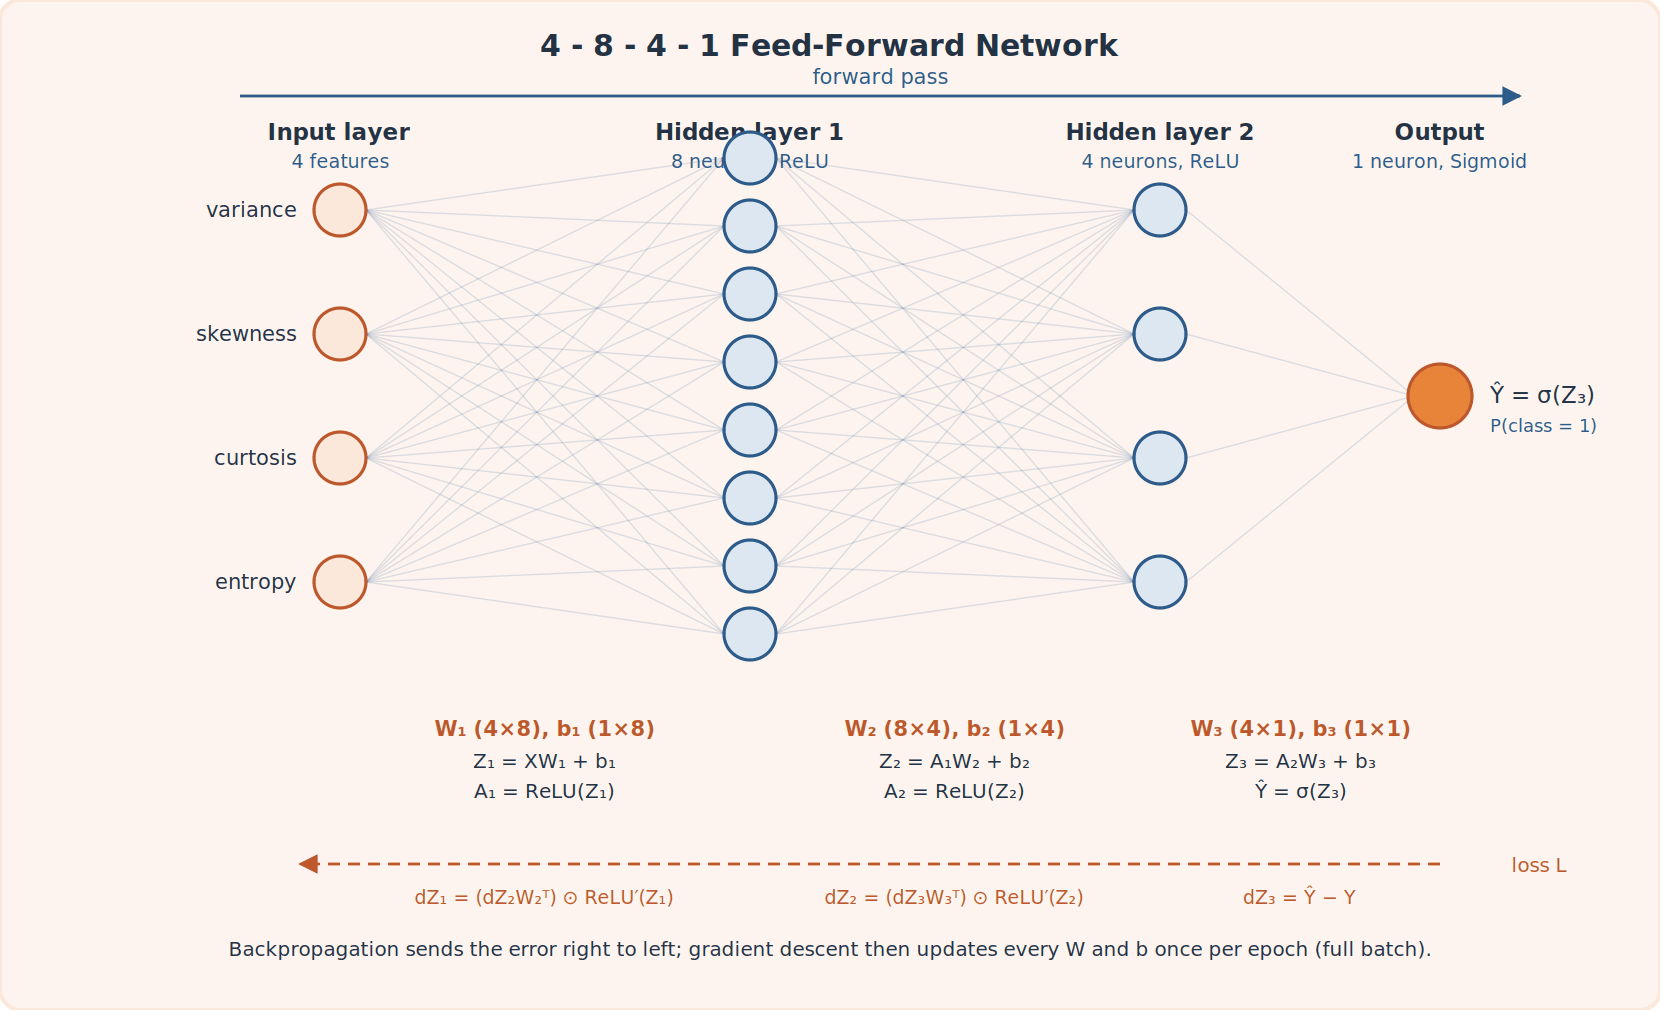

**How to read the diagram.** Each circle is a neuron and each faint line is one weight. The four input circles carry the raw features; the two shaded columns are the hidden ReLU layers; the single orange circle at the right produces the probability that the banknote belongs to class 1.

Counting the lines gives the size of the model: $4\times8 + 8\times4 + 4\times1 = 68$ weights, plus $8+4+1 = 13$ biases, for **81 trainable parameters**. Every one of them is updated once per epoch by the code below.

The blue arrow along the top is the forward pass, and the dashed rust arrow along the bottom is backpropagation. Read the equations printed in each gap from left to right for the forward pass, then the $dZ$ terms from right to left for the backward pass; the next section states the same equations formally.

## Network and Learning Equations

For $m$ training samples the network has two hidden layers and one output layer:

$$
X \in \mathbb{R}^{m \times 4},
\qquad
W_1 \in \mathbb{R}^{4 \times 8},\; b_1 \in \mathbb{R}^{1 \times 8},
\qquad
W_2 \in \mathbb{R}^{8 \times 4},\; b_2 \in \mathbb{R}^{1 \times 4},
\qquad
W_3 \in \mathbb{R}^{4 \times 1},\; b_3 \in \mathbb{R}^{1 \times 1}
$$

### Forward Pass

$$
Z_1 = XW_1 + b_1, \qquad A_1 = \operatorname{ReLU}(Z_1)
$$

$$
Z_2 = A_1 W_2 + b_2, \qquad A_2 = \operatorname{ReLU}(Z_2)
$$

$$
Z_3 = A_2 W_3 + b_3, \qquad \hat{Y} = \sigma(Z_3)
$$

Binary cross-entropy loss:

$$
L =
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
Y_i\log(\hat{Y}_i)
+
(1-Y_i)\log(1-\hat{Y}_i)
\right]
$$

### Backward Pass

For a Sigmoid output trained with binary cross-entropy, the derivative of the loss with respect to $Z_3$ simplifies to

$$
dZ_3 = \hat{Y}-Y
$$

$$
dW_3 = \frac{1}{m}A_2^T dZ_3,
\qquad
db_3 = \frac{1}{m}\sum_{i=1}^{m} dZ_3
$$

The error then flows backwards through hidden layer 2:

$$
dA_2 = dZ_3 W_3^T,
\qquad
dZ_2 = dA_2 \odot \operatorname{ReLU}'(Z_2)
$$

$$
dW_2 = \frac{1}{m}A_1^T dZ_2,
\qquad
db_2 = \frac{1}{m}\sum_{i=1}^{m} dZ_2
$$

and through hidden layer 1:

$$
dA_1 = dZ_2 W_2^T,
\qquad
dZ_1 = dA_1 \odot \operatorname{ReLU}'(Z_1)
$$

$$
dW_1 = \frac{1}{m}X^T dZ_1,
\qquad
db_1 = \frac{1}{m}\sum_{i=1}^{m} dZ_1
$$

Every $dW_\ell$ has the same shape as $W_\ell$, and every $db_\ell$ the same shape as $b_\ell$ (verified against numerical gradients).

### Gradient Descent

$$
W_\ell \leftarrow W_\ell-\alpha\, dW_\ell,
\qquad
b_\ell \leftarrow b_\ell-\alpha\, db_\ell,
\qquad \ell \in \{1,2,3\}
$$

After the parameters are updated, the next epoch performs another forward pass using the updated values.

# Activation Functions, Loss Function, and Parameter Initialization

The hidden weights use **He initialization** ($\sqrt{2/n_{\text{in}}}$), which keeps the variance of ReLU activations stable across layers; the output weights use $\sqrt{1/n_{\text{in}}}$.

In [6]:
def relu(z):
    return np.maximum(0.0, z)


def relu_derivative(z):
    return (z > 0).astype(float)


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-8
    y_pred = np.clip(y_pred, epsilon, 1.0 - epsilon)

    return -np.mean(
        y_true * np.log(y_pred)
        + (1.0 - y_true) * np.log(1.0 - y_pred)
    )


def initialize_parameters(seed=SEED):
    # A local Generator: reproducible weights without touching NumPy's global state
    generator = np.random.default_rng(seed)

    W1 = generator.standard_normal((4, 8)) * np.sqrt(2.0 / 4)
    b1 = np.zeros((1, 8))

    W2 = generator.standard_normal((8, 4)) * np.sqrt(2.0 / 8)
    b2 = np.zeros((1, 4))

    W3 = generator.standard_normal((4, 1)) * np.sqrt(1.0 / 4)
    b3 = np.zeros((1, 1))

    return W1, b1, W2, b2, W3, b3


W1, b1, W2, b2, W3, b3 = initialize_parameters()

learning_rate = 0.08
number_of_samples = len(X_train)

print("W1:", W1.shape, "b1:", b1.shape)
print("W2:", W2.shape, "b2:", b2.shape)
print("W3:", W3.shape, "b3:", b3.shape)

W1: (4, 8) b1: (1, 8)
W2: (8, 4) b2: (1, 4)
W3: (4, 1) b3: (1, 1)


In [7]:
generator = np.random.default_rng(7)
W1 = generator.standard_normal((2, 2))

In [8]:
W1

array([[ 0.00123015,  0.29874554],
       [-0.27413786, -0.89059184]])

In [9]:
# Loss reduction through repeated gradient-descent updates

# Start from the same initial weights and biases
W1, b1, W2, b2, W3, b3 = initialize_parameters()

learning_steps = 50
loss_steps = []

for step in range(learning_steps + 1):

    # ================= FORWARD PASS =================

    # Hidden layer 1
    Z1 = X_train @ W1 + b1
    A1 = relu(Z1)

    # Hidden layer 2
    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    # Output layer
    Z3 = A2 @ W3 + b3
    Y_hat = sigmoid(Z3)

    # Calculate and save loss
    loss = binary_cross_entropy(y_train, Y_hat)
    loss_steps.append(loss)

    # Stop after recording the final loss
    if step == learning_steps:
        break

    # ================= BACKWARD PASS =================

    # Output layer gradients
    dZ3 = Y_hat - y_train
    dW3 = (A2.T @ dZ3) / number_of_samples
    db3 = np.mean(dZ3, axis=0, keepdims=True)   # mean over samples = sum/m

    # Hidden layer 2 gradients
    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * relu_derivative(Z2)
    dW2 = (A1.T @ dZ2) / number_of_samples
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    # Hidden layer 1 gradients
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = (X_train.T @ dZ1) / number_of_samples
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # ================= GRADIENT DESCENT =================

    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1

    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    W3 = W3 - learning_rate * dW3
    b3 = b3 - learning_rate * db3


# ================= RESULTS =================

initial_loss = loss_steps[0]
final_loss = loss_steps[-1]

loss_reduction = initial_loss - final_loss
percentage_reduction = (loss_reduction / initial_loss) * 100

print("Initial loss:       ", round(initial_loss, 6))
print("Final loss:         ", round(final_loss, 6))
print("Loss reduction:     ", round(loss_reduction, 6))
print("Percentage reduced: ", round(percentage_reduction, 2), "%")

print("\nGradient dimensions:")
print("dW1:", dW1.shape, "db1:", db1.shape)
print("dW2:", dW2.shape, "db2:", db2.shape)
print("dW3:", dW3.shape, "db3:", db3.shape)

Initial loss:        0.765457
Final loss:          0.635719
Loss reduction:      0.129738
Percentage reduced:  16.95 %

Gradient dimensions:
dW1: (4, 8) db1: (1, 8)
dW2: (8, 4) db2: (1, 4)
dW3: (4, 1) db3: (1, 1)


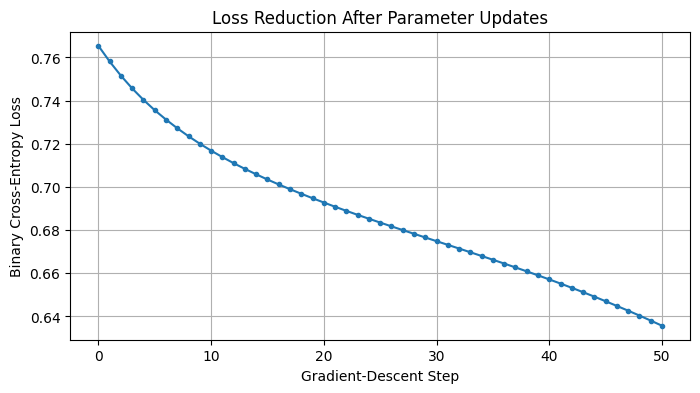

In [10]:
# ================= LOSS VISUALIZATION =================

plt.figure(figsize=(8, 4))
plt.plot(range(learning_steps + 1), loss_steps, marker="o", markersize=3)
plt.xlabel("Gradient-Descent Step")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Loss Reduction After Parameter Updates")
plt.grid()
plt.show()

In [11]:
# Reinitialize before complete training
W1, b1, W2, b2, W3, b3 = initialize_parameters()

epochs = 200
number_of_samples = len(X_train)

train_loss_history = []
validation_loss_history = []
train_accuracy_history = []
validation_accuracy_history = []

for epoch in range(1, epochs + 1):

    # ================= Forward pass =================
    Z1 = X_train @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    Z3 = A2 @ W3 + b3
    Y_hat = sigmoid(Z3)

    # ================= Backward pass =================
    dZ3 = Y_hat - y_train
    dW3 = (A2.T @ dZ3) / number_of_samples
    db3 = np.mean(dZ3, axis=0, keepdims=True)

    dZ2 = (dZ3 @ W3.T) * relu_derivative(Z2)
    dW2 = (A1.T @ dZ2) / number_of_samples
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * relu_derivative(Z1)
    dW1 = (X_train.T @ dZ1) / number_of_samples
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # ================= Gradient descent =================
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3

    # ================= Metrics after the update =================
    # One extra forward pass so the recorded loss/accuracy describe the
    # network as it exists AFTER this epoch's update (the gradients above
    # were computed from the pre-update forward pass).
    Z1_train = X_train @ W1 + b1
    A1_train = relu(Z1_train)
    Z2_train = A1_train @ W2 + b2
    A2_train = relu(Z2_train)
    Z3_train = A2_train @ W3 + b3
    train_probabilities = sigmoid(Z3_train)

    train_loss = binary_cross_entropy(y_train, train_probabilities)
    train_predictions = (train_probabilities >= 0.5).astype(int)
    train_accuracy = np.mean(train_predictions == y_train)

    # ================= Validation result =================
    Z1_val = X_validation @ W1 + b1
    A1_val = relu(Z1_val)
    Z2_val = A1_val @ W2 + b2
    A2_val = relu(Z2_val)
    Z3_val = A2_val @ W3 + b3
    validation_probabilities = sigmoid(Z3_val)

    validation_loss = binary_cross_entropy(y_validation, validation_probabilities)
    validation_predictions = (validation_probabilities >= 0.5).astype(int)
    validation_accuracy = np.mean(validation_predictions == y_validation)

    # Save history
    train_loss_history.append(train_loss)
    validation_loss_history.append(validation_loss)
    train_accuracy_history.append(train_accuracy)
    validation_accuracy_history.append(validation_accuracy)

    if epoch == 1 or epoch % 50 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train loss: {train_loss:.5f} | "
            f"Validation loss: {validation_loss:.5f} | "
            f"Train accuracy: {train_accuracy:.4f} | "
            f"Validation accuracy: {validation_accuracy:.4f}"
        )

Epoch   1 | Train loss: 0.75817 | Validation loss: 0.76043 | Train accuracy: 0.2740 | Validation accuracy: 0.2476
Epoch  50 | Train loss: 0.63572 | Validation loss: 0.64934 | Train accuracy: 0.5583 | Validation accuracy: 0.5194
Epoch 100 | Train loss: 0.43302 | Validation loss: 0.45080 | Train accuracy: 0.9000 | Validation accuracy: 0.8835
Epoch 150 | Train loss: 0.24732 | Validation loss: 0.25576 | Train accuracy: 0.9542 | Validation accuracy: 0.9612
Epoch 200 | Train loss: 0.13138 | Validation loss: 0.13734 | Train accuracy: 0.9802 | Validation accuracy: 0.9757


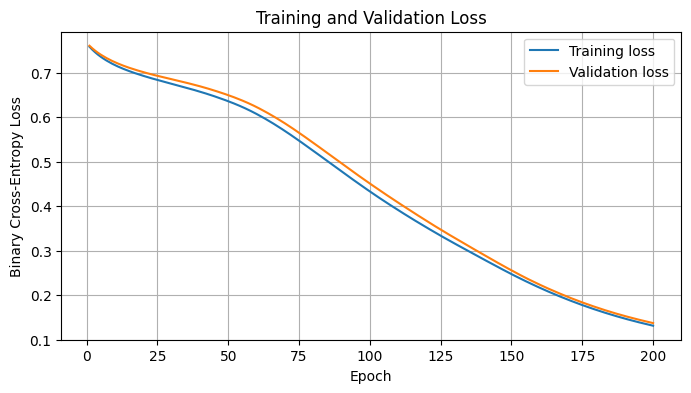

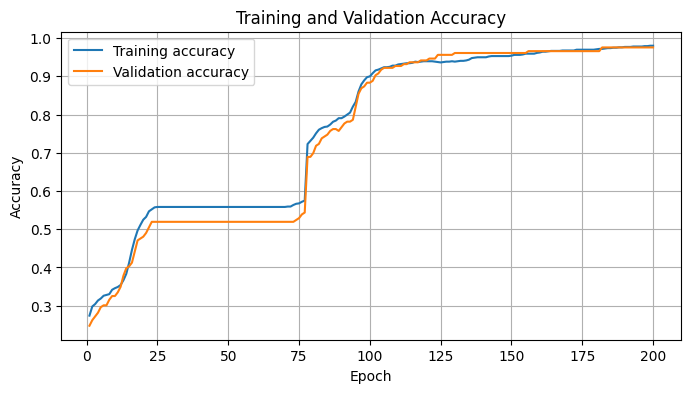

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_loss_history, label="Training loss")
plt.plot(range(1, epochs + 1), validation_loss_history, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_accuracy_history, label="Training accuracy")
plt.plot(range(1, epochs + 1), validation_accuracy_history, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

Notice the flat stretch up to roughly epoch 60: training accuracy is pinned at exactly 0.5583, which is the fraction of class-0 samples in this training split (536 of 960). During those epochs the network predicts class 0 for every sample while gradient descent slowly reshapes the hidden layers; once the output starts to differentiate, accuracy climbs quickly. Exercise 3 at the end of the notebook investigates this plateau.

In [13]:
# Test-set evaluation

Z1 = X_test @ W1 + b1
A1 = relu(Z1)

Z2 = A1 @ W2 + b2
A2 = relu(Z2)

Z3 = A2 @ W3 + b3
probabilities = sigmoid(Z3)

predictions = (probabilities >= 0.5).astype(int)

accuracy = np.mean(predictions == y_test)

tn = np.sum((y_test == 0) & (predictions == 0))
fp = np.sum((y_test == 0) & (predictions == 1))
fn = np.sum((y_test == 1) & (predictions == 0))
tp = np.sum((y_test == 1) & (predictions == 1))

assert tn + fp + fn + tp == len(y_test)  # every test sample counted once

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
))

Accuracy:  0.9757
Precision: 0.9767
Recall:    0.9655
F1-score:  0.9711


,Predicted 0,Predicted 1
Actual 0,117,2
Actual 1,3,84


## Decision Boundaries: What the Network Actually Learns

A binary classifier splits feature space into two regions. The **decision boundary** is the set of points where the model is exactly undecided:

$$
\{\, x \;:\; \hat{p}(x) = 0.5 \,\}
$$

Our network lives in a 4-dimensional feature space, so its boundary is a 3-dimensional surface that cannot be drawn. To *see* a boundary, we train the same kind of network on only **two** features — `variance` and `skewness`, the two most discriminative ones — and plot the boundary in that plane.

One warning before we start: a PCA or t-SNE scatter plot of the data is **not** a decision boundary. Those plots show where the data sits, not where a trained model separates the classes. A boundary can only be drawn in the exact space the model was trained on.

The code below is the same algorithm as above (forward pass, backpropagation, gradient descent), written once for an arbitrary list of layer sizes so we can compare several architectures without repeating fifty lines per network.

In [14]:
# Generalized version of the network above: works for any layer sizes,
# e.g. [2, 1] (no hidden layer) or [2, 8, 4, 1] (two hidden layers).

def init_params(layer_sizes, seed=SEED):
    generator = np.random.default_rng(seed)
    params = []
    for i in range(len(layer_sizes) - 1):
        fan_in = layer_sizes[i]
        # He initialization for hidden layers, sqrt(1/n) for the output layer
        scale = np.sqrt(2.0 / fan_in) if i < len(layer_sizes) - 2 \
            else np.sqrt(1.0 / fan_in)
        W = generator.standard_normal((layer_sizes[i], layer_sizes[i + 1])) * scale
        b = np.zeros((1, layer_sizes[i + 1]))
        params.append([W, b])
    return params


def forward_all(params, X_in):
    """Return every pre-activation Z and activation A (A[0] is the input)."""
    Zs, As = [], [X_in]
    for i, (W, b) in enumerate(params):
        Z = As[-1] @ W + b
        Zs.append(Z)
        As.append(sigmoid(Z) if i == len(params) - 1 else relu(Z))
    return Zs, As


def predict_proba(params, X_in):
    return forward_all(params, X_in)[1][-1]


def train_network(X_in, y_in, layer_sizes, epochs, lr, seed=SEED, snapshot_at=()):
    """Full-batch gradient descent; optionally save parameter snapshots."""
    params = init_params(layer_sizes, seed)
    m = len(X_in)
    snapshots = {}
    if 0 in snapshot_at:
        snapshots[0] = [[W.copy(), b.copy()] for W, b in params]

    for epoch in range(1, epochs + 1):
        Zs, As = forward_all(params, X_in)
        dZ = As[-1] - y_in                       # sigmoid + BCE shortcut
        for i in range(len(params) - 1, -1, -1):
            dW = (As[i].T @ dZ) / m
            db = np.mean(dZ, axis=0, keepdims=True)
            if i > 0:                            # propagate before updating W
                dZ = (dZ @ params[i][0].T) * relu_derivative(Zs[i - 1])
            params[i][0] -= lr * dW
            params[i][1] -= lr * db
        if epoch in snapshot_at:
            snapshots[epoch] = [[W.copy(), b.copy()] for W, b in params]
    return params, snapshots


def accuracy_of(params, X_in, y_in):
    return np.mean((predict_proba(params, X_in) >= 0.5) == y_in)


def plot_boundary(ax, params, X_in, y_in, title, levels=(0.5,)):
    """Shade the two predicted regions, draw probability contours, scatter data."""
    x_min, x_max = X_in[:, 0].min() - 0.7, X_in[:, 0].max() + 0.7
    y_min, y_max = X_in[:, 1].min() - 0.7, X_in[:, 1].max() + 0.7
    gx, gy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid_probabilities = predict_proba(
        params, np.c_[gx.ravel(), gy.ravel()]
    ).reshape(gx.shape)

    ax.contourf(gx, gy, grid_probabilities, levels=[0, 0.5, 1],
                colors=["#aecbe8", "#f2b8a2"], alpha=0.55)
    contour_set = ax.contour(
        gx, gy, grid_probabilities, levels=list(levels), colors="k",
        linewidths=[2 if lv == 0.5 else 1 for lv in levels],
        linestyles=["solid" if lv == 0.5 else "dashed" for lv in levels])
    if len(levels) > 1:
        ax.clabel(contour_set, fmt="p=%.1f", fontsize=8)

    mask0 = (y_in.ravel() == 0)
    mask1 = (y_in.ravel() == 1)
    ax.scatter(X_in[mask0, 0], X_in[mask0, 1], s=10, c="#2D5B8A", label="class 0")
    ax.scatter(X_in[mask1, 0], X_in[mask1, 1], s=10, c="#BD582C", label="class 1")
    ax.set_xlabel("variance (standardized)")
    ax.set_ylabel("skewness (standardized)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="lower left")


# Two-feature versions of the (already standardized) splits
X2_train = X_train[:, :2]
X2_test = X_test[:, :2]
print("2-feature training set:", X2_train.shape)

2-feature training set: (960, 2)


### Experiment 1 — Impact of the hidden layers

We train two models on the same two features: a network with **no hidden layer** (a single sigmoid neuron, which is logistic regression) and the **2–8–4–1 network**. The linear model can only draw a straight line. The ReLU network composes piecewise-linear functions, so its boundary is a chain of straight segments — look for the kinks.

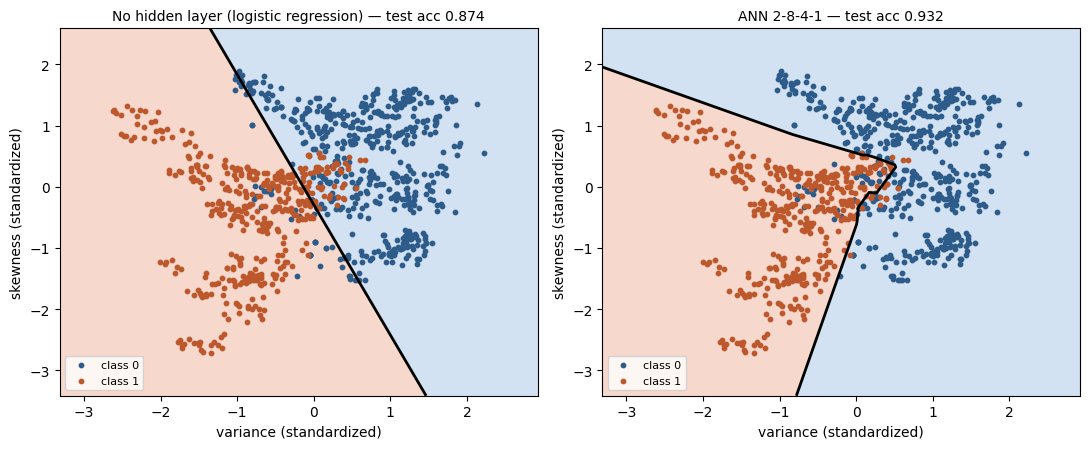

Accuracy gained by the hidden layers: 5.8 percentage points


In [15]:
linear_params, _ = train_network(X2_train, y_train, [2, 1],
                                 epochs=3000, lr=0.5)
ann_params, ann_snapshots = train_network(X2_train, y_train, [2, 8, 4, 1],
                                          epochs=3000, lr=0.08,
                                          snapshot_at=(0, 100, 500, 3000))

linear_accuracy = accuracy_of(linear_params, X2_test, y_test)
ann_accuracy = accuracy_of(ann_params, X2_test, y_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_boundary(axes[0], linear_params, X2_train, y_train,
              f"No hidden layer (logistic regression) — test acc {linear_accuracy:.3f}")
plot_boundary(axes[1], ann_params, X2_train, y_train,
              f"ANN 2-8-4-1 — test acc {ann_accuracy:.3f}")
fig.tight_layout()
plt.show()

print(f"Accuracy gained by the hidden layers: "
      f"{(ann_accuracy - linear_accuracy) * 100:.1f} percentage points")

The line misclassifies the class-1 points that curl around the class-0 cloud; the network bends its boundary to follow them. That bend is what the hidden layers buy. Note that both models here see only 2 of the 4 features, which is why neither reaches the ~97% the full network achieved earlier — the other two features carry real information.

### Experiment 2 — Impact of training on the boundary

The boundary is not designed; it *emerges* from gradient descent. Below are snapshots of the same network at initialization and after 100, 500, and 3000 epochs. At epoch 0 the boundary is an arbitrary near-linear cut — its accuracy can even be worse than always guessing the majority class.

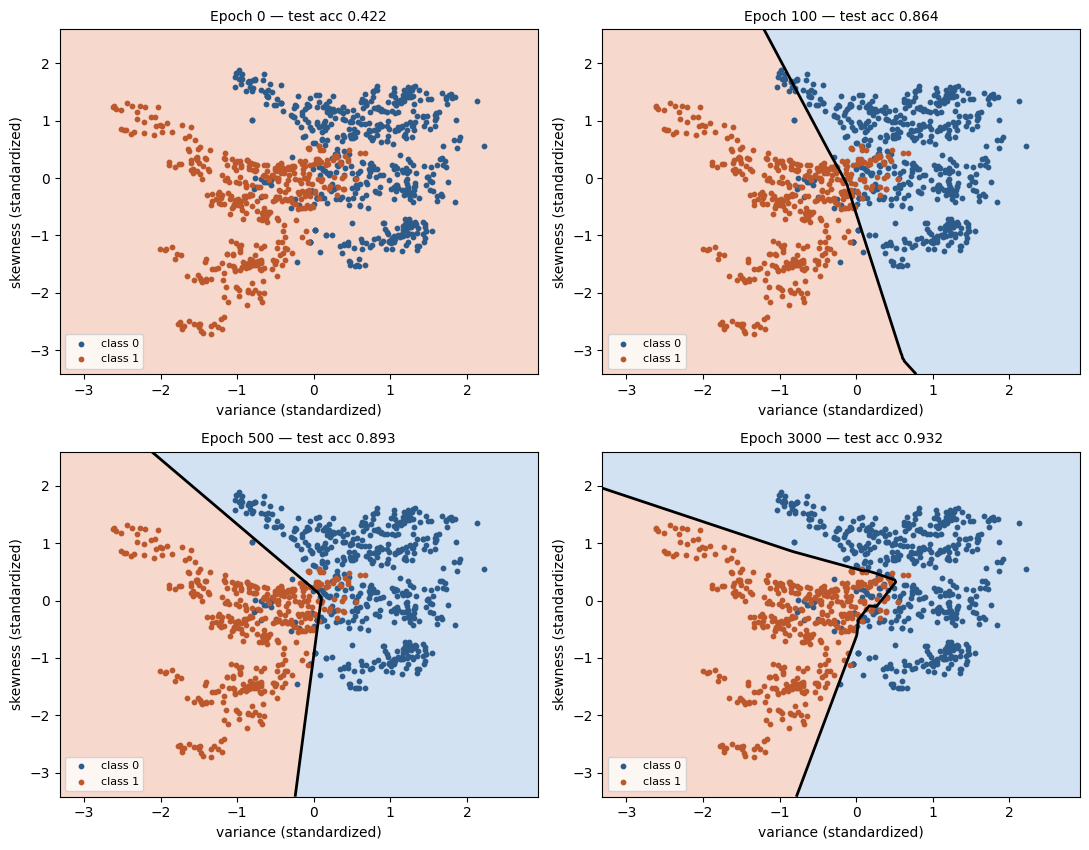

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.6))
for ax, epoch in zip(axes.ravel(), (0, 100, 500, 3000)):
    snapshot_params = ann_snapshots[epoch]
    snapshot_accuracy = accuracy_of(snapshot_params, X2_test, y_test)
    plot_boundary(ax, snapshot_params, X2_train, y_train,
                  f"Epoch {epoch} — test acc {snapshot_accuracy:.3f}")
fig.tight_layout()
plt.show()

### Experiment 3 — Impact of network capacity

Width controls how many kinks the boundary can have. One hidden ReLU neuron adds exactly one kink to the linear model; 32 neurons allow a finely contoured region. On this dataset extra capacity keeps helping a little, but on noisier data a very flexible boundary starts wrapping around individual points — overfitting made visible.

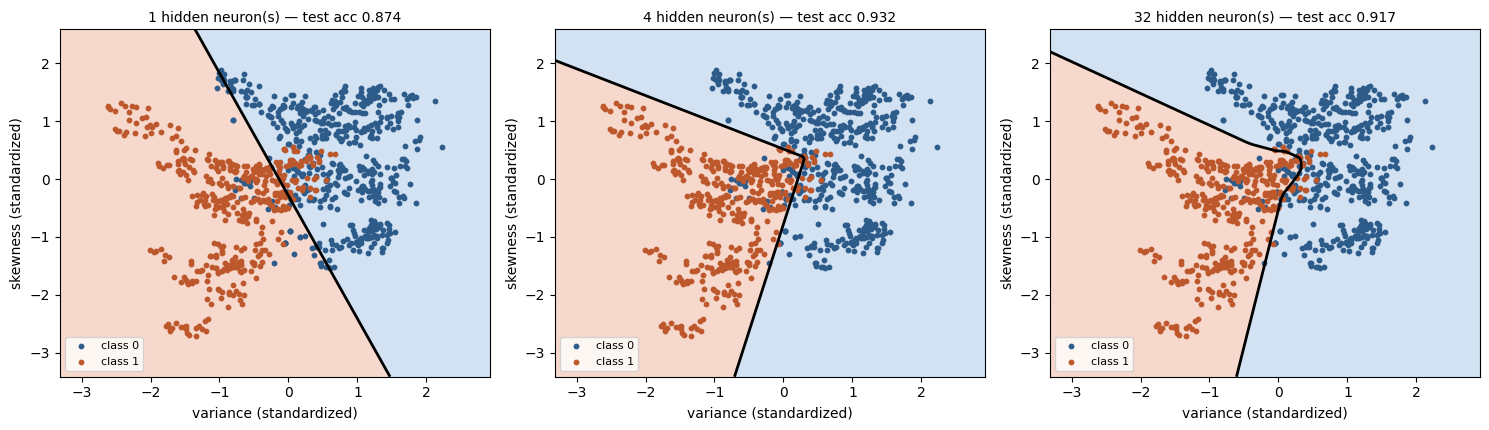

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, hidden_neurons in zip(axes, (1, 4, 32)):
    capacity_params, _ = train_network(X2_train, y_train,
                                       [2, hidden_neurons, 1],
                                       epochs=3000, lr=0.08)
    capacity_accuracy = accuracy_of(capacity_params, X2_test, y_test)
    plot_boundary(ax, capacity_params, X2_train, y_train,
                  f"{hidden_neurons} hidden neuron(s) — "
                  f"test acc {capacity_accuracy:.3f}")
fig.tight_layout()
plt.show()

### Experiment 4 — Impact of the decision threshold

The trained network outputs a probability; the boundary we drew is just its 0.5 contour. Choosing a different threshold slides the boundary without retraining. Lowering it to 0.3 grows the "predict 1" region (recall on class 1 rises, precision falls); raising it to 0.7 shrinks that region (precision rises, recall falls). This is the geometric picture behind the precision–recall trade-off measured on the test set earlier.

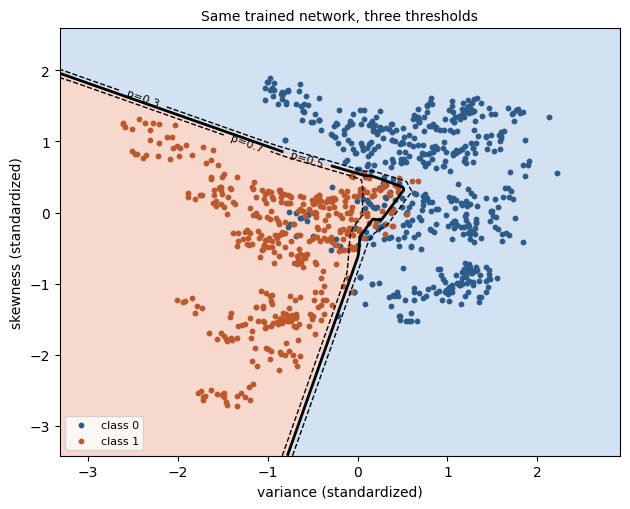

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 5.2))
plot_boundary(ax, ann_params, X2_train, y_train,
              "Same trained network, three thresholds",
              levels=(0.3, 0.5, 0.7))
fig.tight_layout()
plt.show()

### Exercises

1. Replace `variance` and `skewness` with `curtosis` and `entropy` (`X_train[:, 2:4]`). Retrain both models in Experiment 1 and explain the accuracy drop using the plot.
2. In Experiment 3, add a network with 200 hidden neurons and train for 10,000 epochs. Does the boundary change shape near isolated points? Compare training and test accuracy.
3. The default run (`seed=42`) plateaus at accuracy 0.5583 — the majority-class rate — for about 60 epochs. Rerun the main 4-feature training with `initialize_parameters(seed=7)`; that run reaches 0.92 within 25 epochs with no plateau. Both use identical data, architecture, and learning rate. Explain what property of the initial weights causes the difference, and what the network is predicting during the plateau.
4. Count the visible kinks on the 1-hidden-neuron boundary and on the 4-neuron boundary. State the relationship between hidden ReLU units and the maximum number of linear pieces in this 2-D setting.
5. Using the threshold plot, predict what happens to the confusion matrix if the threshold is set to 0.3, then verify by recomputing it on the test set.

## Conclusion

The network follows the complete learning cycle:

$$
\text{Forward Pass}
\rightarrow
\text{Loss}
\rightarrow
\text{Backward Pass}
\rightarrow
\text{Gradient Descent}
\rightarrow
\text{Next Forward Pass}
$$

The forward pass produces the prediction and loss. Backpropagation applies the chain rule to calculate the gradients of the weights and biases. Gradient descent then updates those parameters. The next epoch repeats the forward pass with the updated parameter values. The decision-boundary experiments show what this loop produces geometrically: gradient descent gradually bends an initially arbitrary separating surface until it follows the shape of the data, with the network's depth and width setting how much bending is possible.